# PS04-AI — Mẫu hồi quy: sửa cấu hình rồi chạy
**Nguyễn Bích Vân -IAI-UET-VNU**

Mẫu dùng dữ liệu đồ uống giả lập riêng để học thao tác. Chạy từ trên xuống; mỗi ô Markdown giải thích mục đích của ô mã ngay sau nó. Không dùng Python để thay yêu cầu tính tay Bài 1–6.

## 1. Chuẩn bị kernel
Mở cả thư mục trong VS Code, chọn **Select Kernel → Python Environments**. Nếu thiếu thư viện, thêm một ô Code và chạy `%pip install -r requirements.txt`, rồi **Restart Kernel**. Dấu `>>` của PowerShell không thuộc mã Python.

Các thư viện: pandas đọc bảng, statsmodels khớp OLS, plotnine vẽ hình.

In [2]:
import sys
from pathlib import Path
print("Python của kernel:", sys.executable)
# Nếu thiếu thư viện: chạy %pip install -r requirements.txt trong một ô riêng,
# rồi Restart Kernel. Không dán dấu PS ...> hoặc >> vào notebook.
import numpy as np
import pandas as pd
import plotnine
import statsmodels
from IPython.display import display
from plotnine import (ggplot, aes, geom_point, geom_line, geom_abline,
                      geom_hline, labs, facet_wrap)
ROOT_OVERRIDE = ""  # Ví dụ r"D:\PS04_AI_Student"; để trống khi mở đúng thư mục.
ROOT = Path(ROOT_OVERRIDE).expanduser() if ROOT_OVERRIDE else Path.cwd()
ROOT = ROOT.resolve()
if not (ROOT / "regression_tools.py").is_file():
    raise FileNotFoundError("Mở thư mục có data/ và regression_tools.py, hoặc sửa ROOT_OVERRIDE.")
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
from regression_tools import prepare_data, analyze, numeric_summary, make_plots, save_plots
print("Thư mục bài:", ROOT)
print("NumPy",np.__version__,"pandas",pd.__version__,"plotnine",plotnine.__version__,"statsmodels",statsmodels.__version__)


Python của kernel: c:\Users\Pro 5\AppData\Local\Programs\Python\Python313\python.exe
Thư mục bài: D:\XSTK 2026\PS04_AI_Student\PS04_AI_Student
NumPy 2.2.5 pandas 2.3.3 plotnine 0.15.3 statsmodels 0.15.0


## 2. Ô duy nhất cần đổi khi thay dữ liệu
`file`: tên CSV trong `data/`; `x`,`y`: tên chính xác của hai cột số; `group`: cột phân loại hoặc `None`; `reference`: một nhãn nhóm hiện có; `x_new`: giá trị để tính dự đoán hoặc `None`. Tên tệp/cột/nhãn có phân biệt chữ hoa và chữ thường.

In [3]:
# Đây là dữ liệu HỌC MẪU, không phải đáp án của Bài 7 hay Bài 9.
CONFIG = {
    "file": "demo_drink_orders.csv",
    "x": "item_count",
    "y": "wait_time_min",
    "group": "service_mode",  # None để chỉ dùng hai biến số
    "reference": "Standard",
    "x_label": "Số món trong đơn",
    "y_label": "Thời gian chờ (phút)",
    "x_new": 3,
}


## 3. Đọc và chọn đúng các cặp hợp lệ
Mã báo số hàng bị loại. Hai mô hình được so sánh trên cùng các hàng: khi dùng biến nhóm, cả mô hình đơn cũng dùng các hàng có nhãn nhóm. Không dùng một mẫu cho tương quan và một mẫu khác cho hồi quy mà không giải thích.

In [4]:
data = prepare_data(ROOT, CONFIG["file"], CONFIG["x"], CONFIG["y"], CONFIG["group"])
display(data.head())
print("Kích thước:", data.shape)
print("Miền x:", data.x.min(),"đến",data.x.max())
# Trong bảng xử lý, x/y/group là bí danh; CSV gốc không bị sửa.


demo_drink_orders.csv: ban đầu 12 hàng; giữ 12; loại 0.
Các hàng bị loại là thiếu/không hợp lệ ở đúng các cột đang dùng; không đổi thành 0.


,x,y,group
0,1,2.638179,Standard
1,2,3.381074,Standard
2,3,4.184371,Standard
3,4,5.064994,Standard
4,5,5.877618,Standard


Kích thước: (12, 3)
Miền x: 1 đến 6


## 4. Học cú pháp plotnine trực tiếp
`ggplot(data, aes(...))` chọn bảng và ánh xạ; `geom_point()` biến một hàng thành một điểm; `labs()` đặt nhãn hiển thị. Tên cột `x`, `y` là bí danh trong bảng xử lý, không phải tên mới được ghi vào CSV.

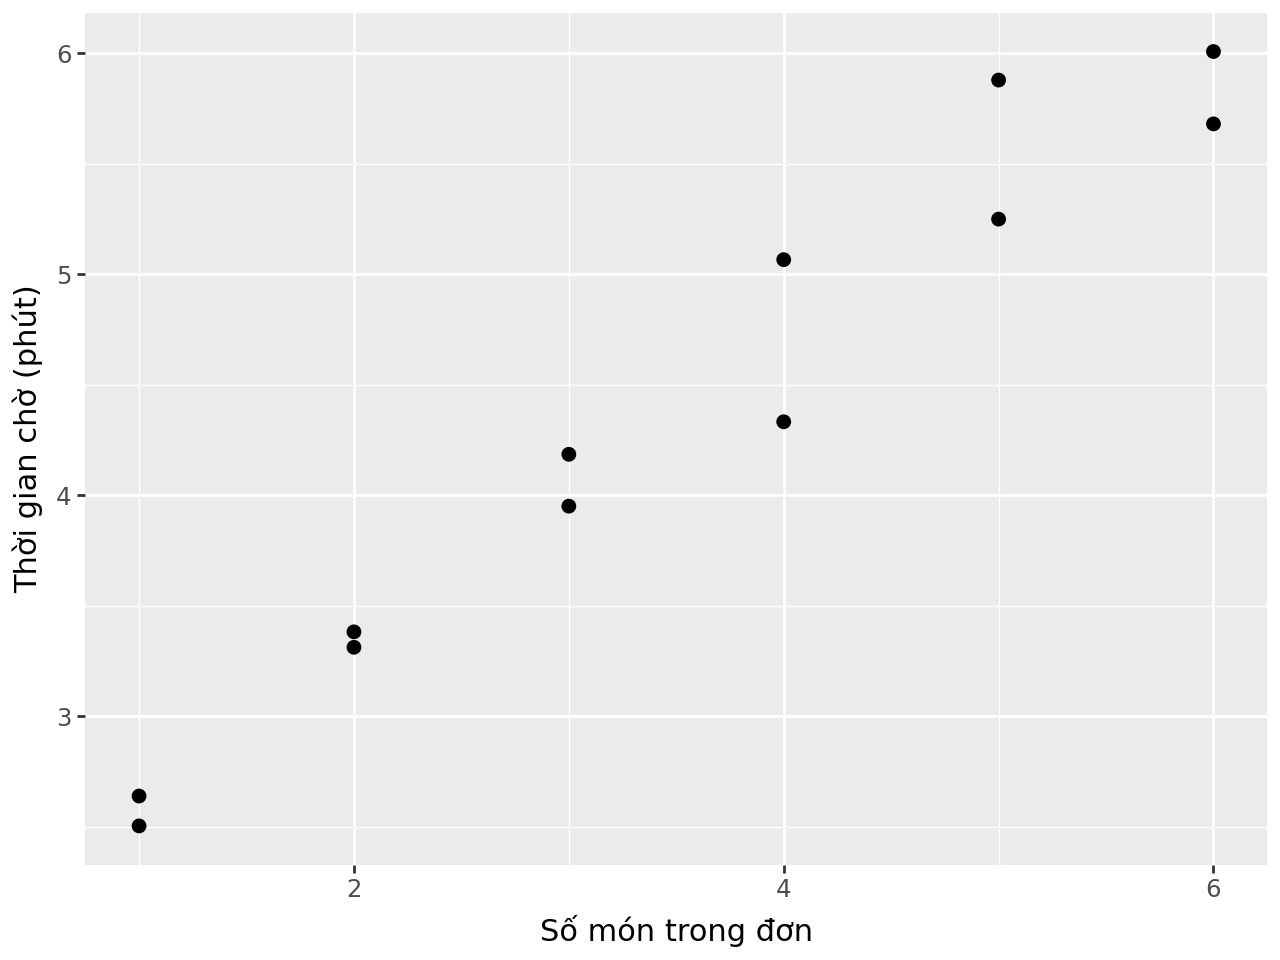

In [5]:
p0 = (ggplot(data, aes(x="x",y="y"))
      + geom_point(size=2)
      + labs(x=CONFIG["x_label"],y=CONFIG["y_label"]))
display(p0)

## 5. Tính r, khớp OLS và đọc các hệ số
Mô hình đơn là `y ~ x`. Khi có nhóm, mô hình cộng thêm các biến chỉ báo, không có tương tác. SSE chỉ so sánh được khi cùng các quan sát và cùng đơn vị y. Tổng phần dư rất gần 0 là sai số máy tính, không cần đúng chuỗi ký tự `0.0`.

In [6]:
result = analyze(data, reference=CONFIG["reference"])
print("Pearson r =", result["r"])
print("Hệ số OLS đơn:")
display(result["simple"].params.to_frame("coefficient"))
if result["adjusted"] is not None:
    print("Mức tham chiếu:", result["reference"])
    display(result["adjusted"].params.to_frame("coefficient"))
display(numeric_summary(result))


Pearson r = 0.9776467328399989
Hệ số OLS đơn:


,coefficient
Intercept,1.983584
x,0.675559


Mức tham chiếu: Standard


,coefficient
Intercept,2.161050
"C(group, Treatment(reference='Standard'))[T.Express]",-0.354931
x,0.675559


,model,n,SSE,sum_residuals,sum_x_residuals
0,simple,12,0.738788,-7.105427e-15,-1.598721e-14
1,adjusted,12,0.360861,1.865175e-14,5.551115e-14


## 6. Tự viết một lớp đường hồi quy
`Intercept` là hệ số chặn; `x` là hệ số góc theo biến x trong bảng xử lý. `geom_abline` vẽ đúng đường đã khớp, không tự khớp mô hình khác.

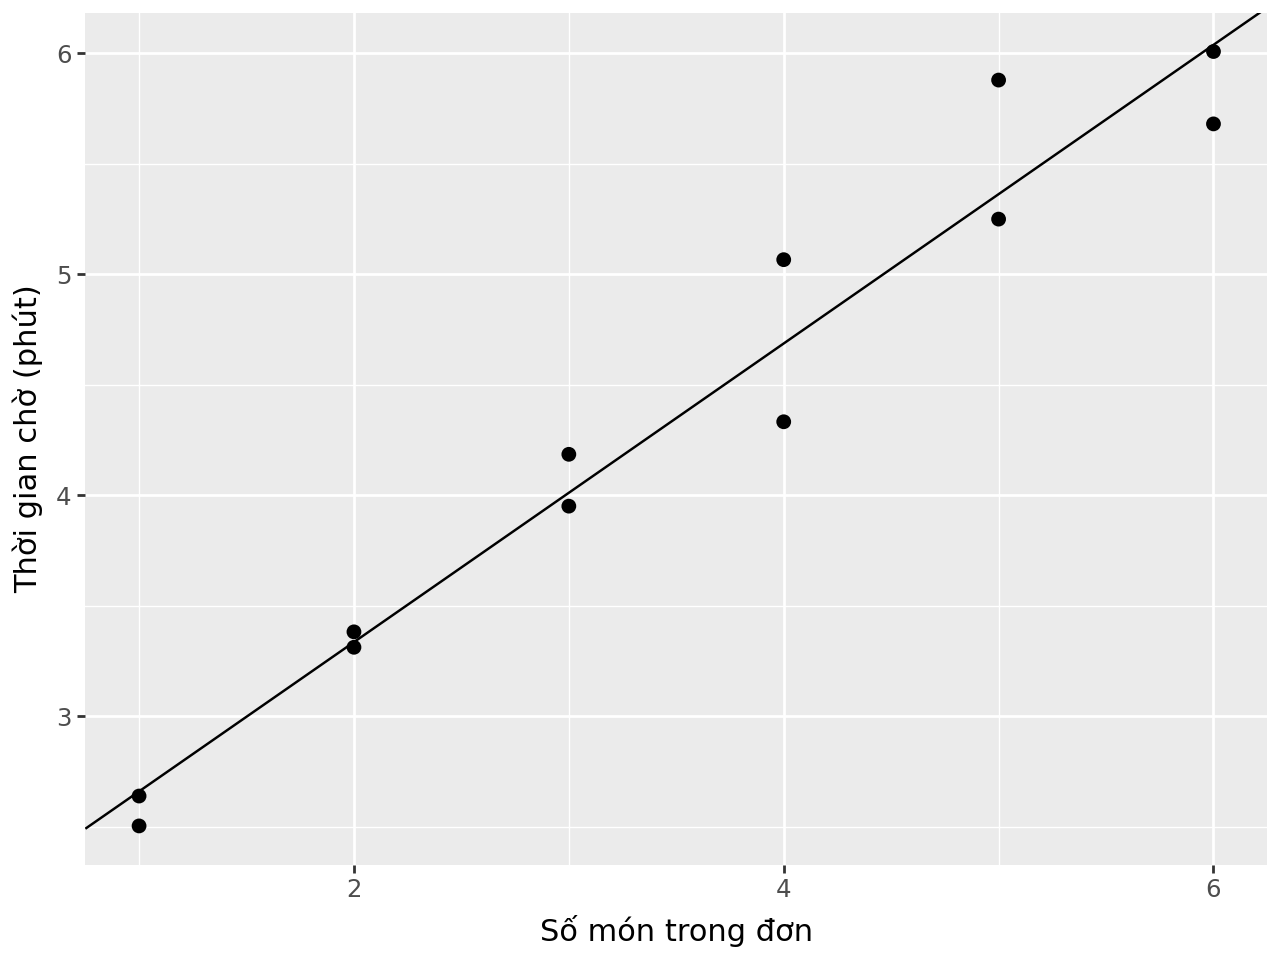

In [7]:
m = result["simple"]
p_fit = (p0 + geom_abline(intercept=m.params["Intercept"],slope=m.params["x"]))
display(p_fit)

## 7. Vẽ hình và đọc phần dư
Thư viện mẫu gói các lệnh lặp lại thành hàm để bạn chỉ đổi cấu hình. Mở `regression_tools.py` để xem đầy đủ cách tạo hình theo lớp. Mô hình nhóm chỉ vẽ mỗi đường trong miền x quan sát của chính nhóm đó.

scatter_and_fit


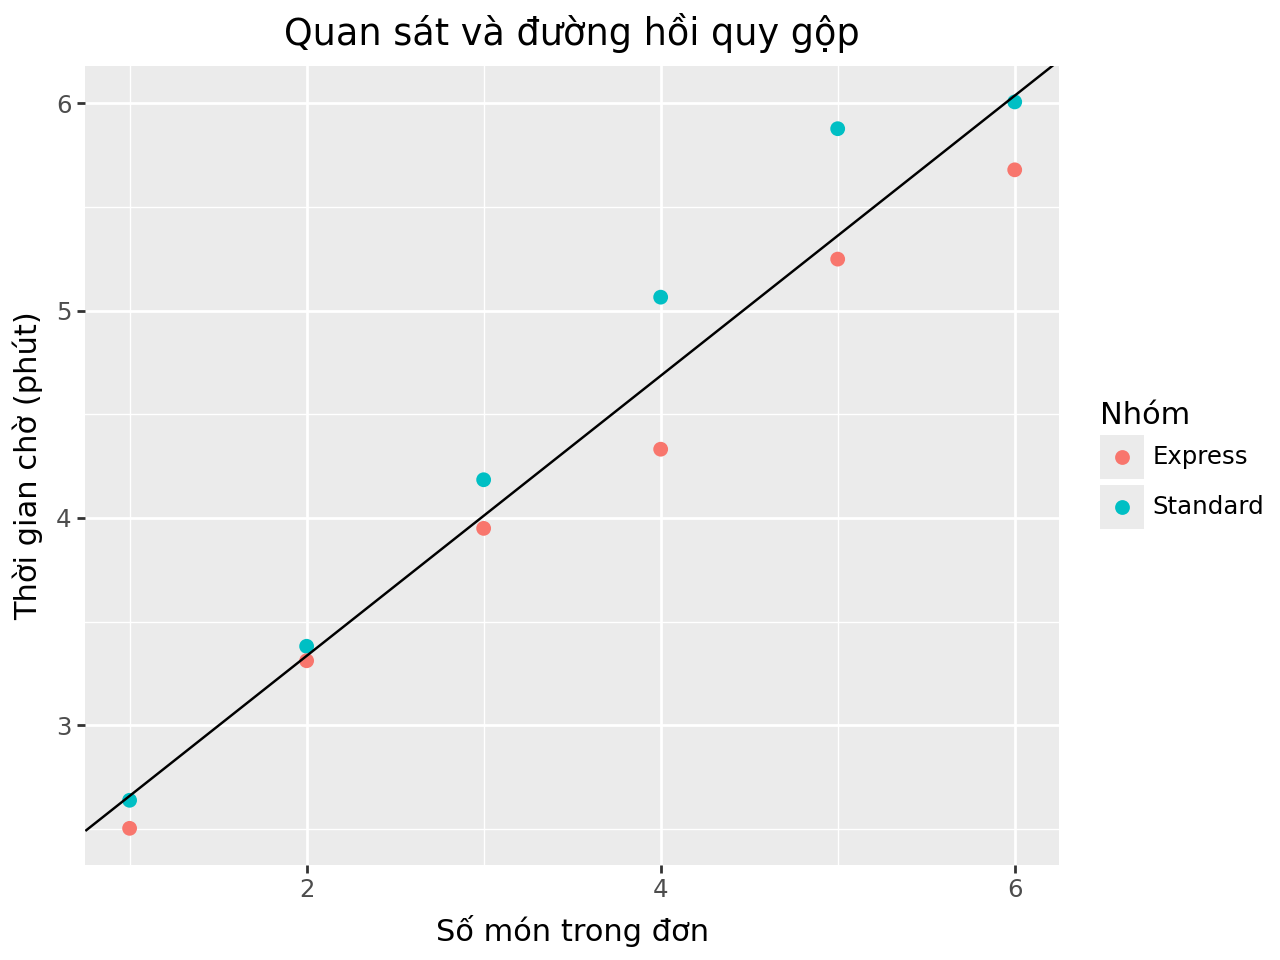

residuals


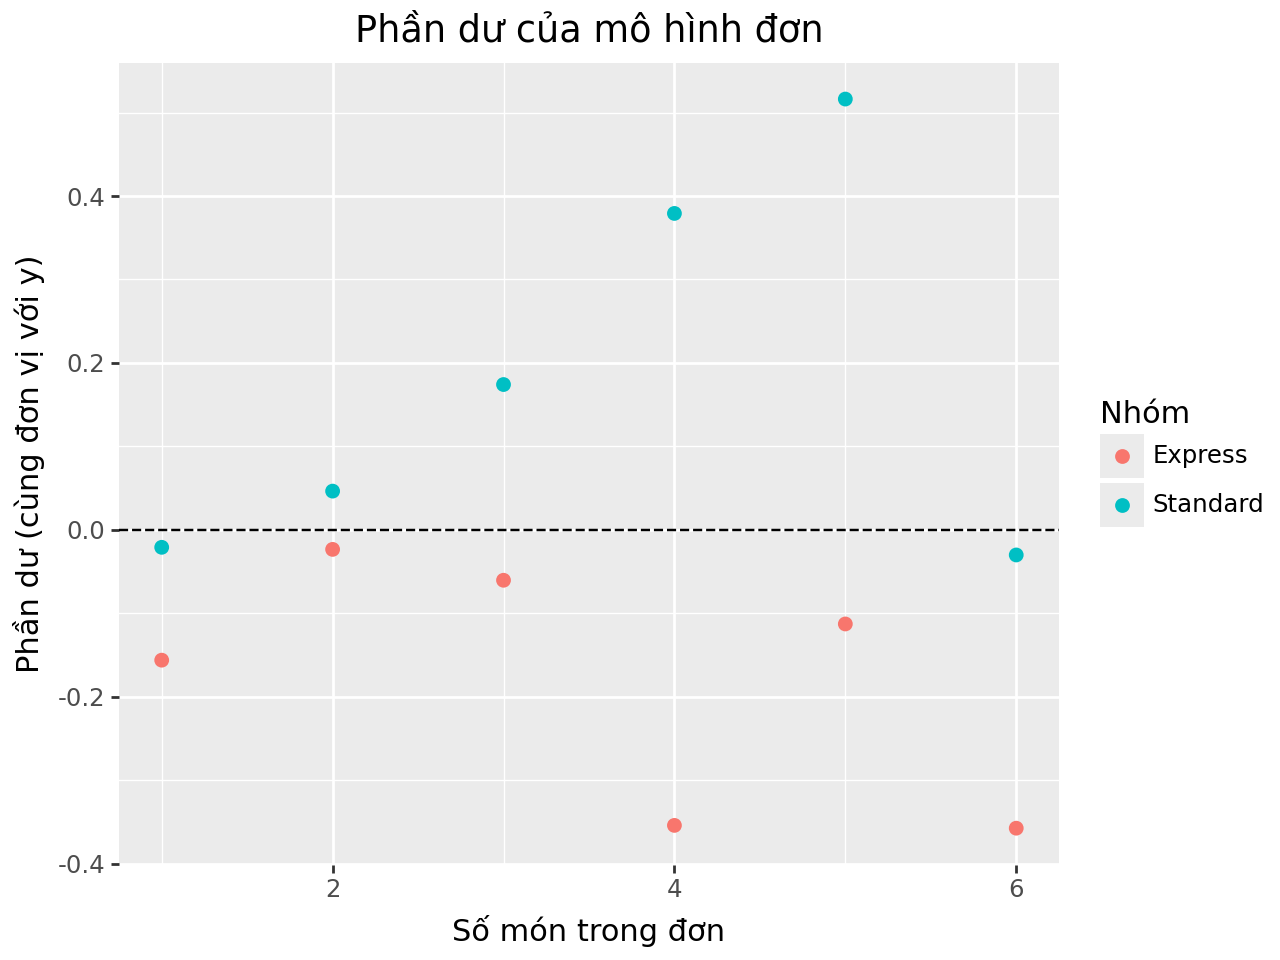

adjusted_fit


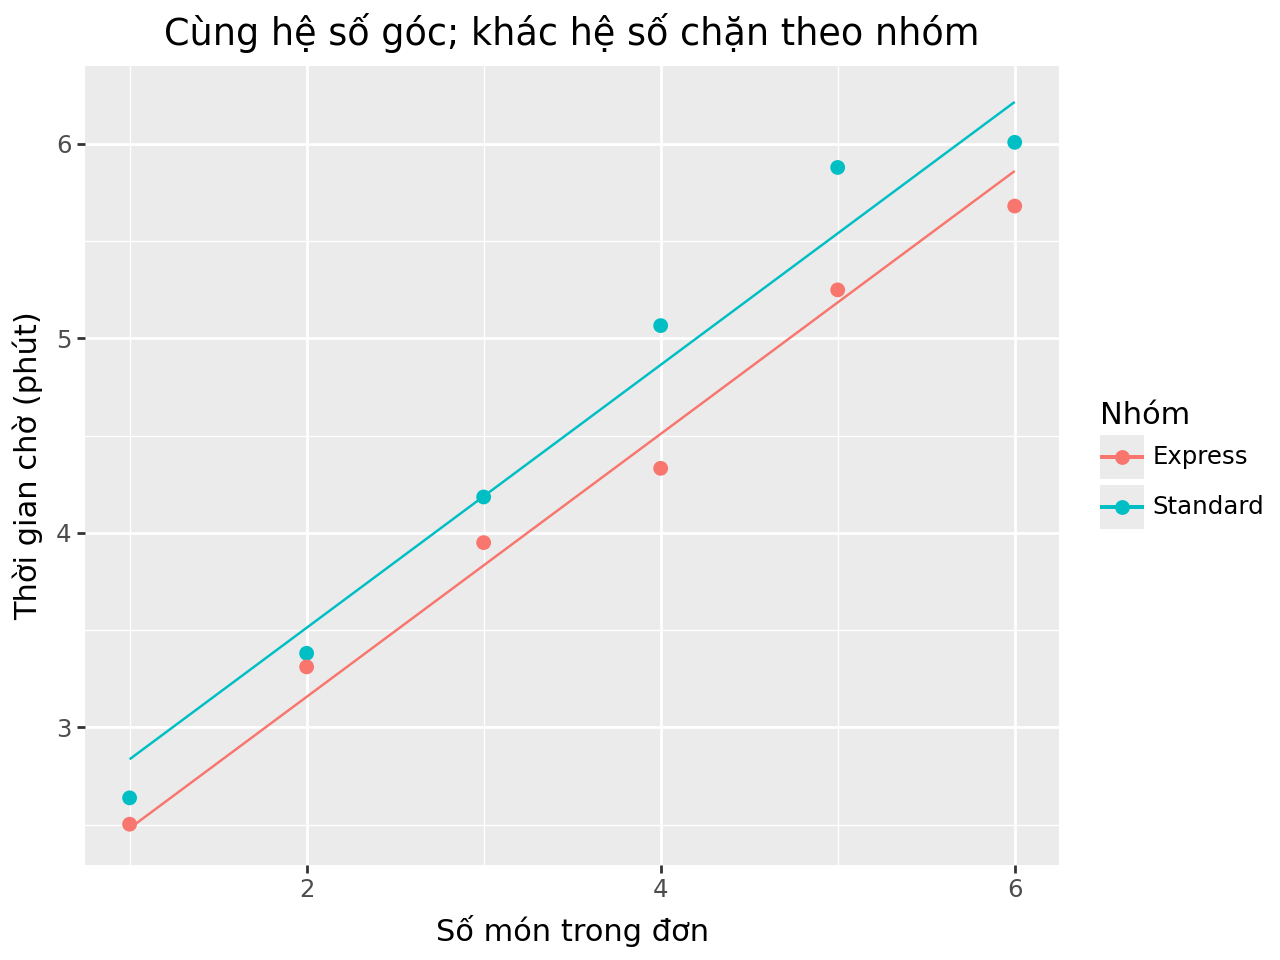

In [8]:
plots = make_plots(result, CONFIG["x_label"], CONFIG["y_label"])
for name, p in plots.items():
    print(name)
    display(p)
# Kết quả hiện NGAY DƯỚI Ô. Không cần cửa sổ riêng hoặc Terminal.


## 8. Tính một giá trị khớp, kiểm tra ngoại suy
Đây không phải giá trị chắc chắn sẽ xảy ra. Khi có nhóm, cần kiểm tra miền x của từng nhóm, không chỉ miền gộp.

In [ ]:
x_new = CONFIG["x_new"]
if x_new is not None:
    if not data.x.min() <= x_new <= data.x.max():
        print("CẢNH BÁO: x_new ngoài miền dữ liệu; đây là ngoại suy.")
    print("Giá trị khớp mô hình đơn:",
          float(result["simple"].predict(pd.DataFrame({"x":[x_new]})).iloc[0]))
    if result["adjusted"] is not None:
        new = pd.DataFrame({"x":[x_new]*data.group.nunique(),
                            "group":sorted(data.group.unique())})
        new["fitted"] = result["adjusted"].predict(new)
        display(new)
        for name, g in data.groupby("group"):
            if not g.x.min() <= x_new <= g.x.max():
                print(f"CẢNH BÁO: x_new ngoài miền đã quan sát của nhóm {name}.")


Giá trị khớp mô hình đơn: 4.010260152833333


,x,group,fitted
0,3,Express,3.832795
1,3,Standard,4.187726


## 9. Mẫu kiểm tra chiều dự đoán (dùng cho LAB02)
Khớp `x ~ y` là bài toán riêng. Nhìn tích hai slope và r bình phương. Hai chiều đo sai số bằng hai đơn vị khác nhau; không so SSE thô để nói chiều nào tốt hơn.

Slope y theo x: 0.6755585909999995
Slope x theo y: 1.4148190060286332
Tích slope: 0.9557931342327233 ; r^2 = 0.9557931342327243
Tâm dữ liệu: 3.5 4.348039448333334


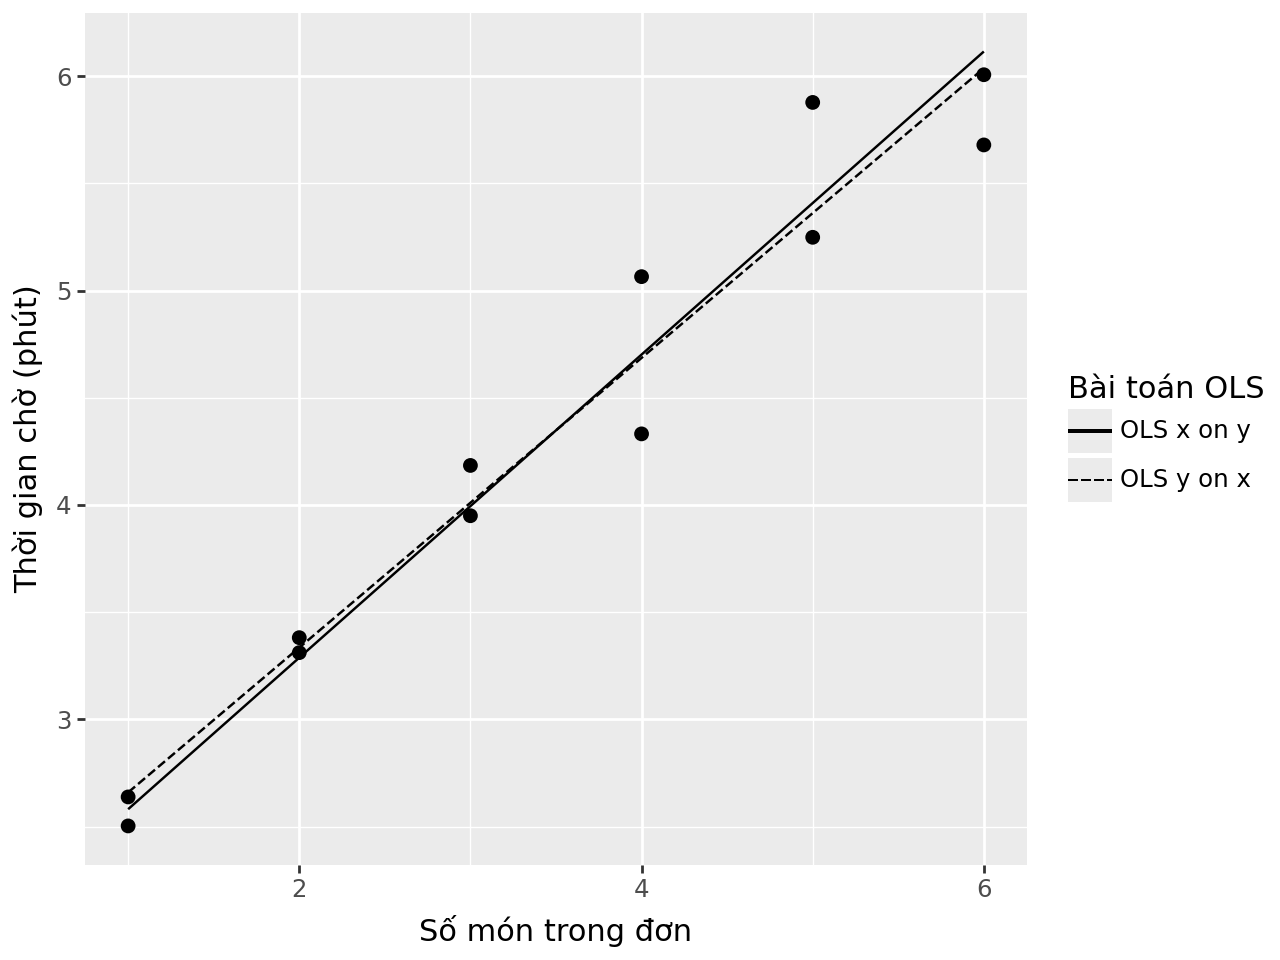

In [ ]:
forward = result["simple"]
reverse = result["reverse"]
b_yx = float(forward.params["x"])
b_xy = float(reverse.params["y"])
print("Slope y theo x:",b_yx)
print("Slope x theo y:",b_xy)
print("Tích slope:",b_yx*b_xy,"; r^2 =",result["r"]**2)
print("Tâm dữ liệu:",data.x.mean(),data.y.mean())
# Chỉ đảo hệ số khác 0. Vẽ cả hai đường trên trục (x,y).
grid = np.linspace(data.x.min(),data.x.max(),80)
lines = pd.DataFrame({"x":grid,"y":forward.params["Intercept"]+b_yx*grid,
                      "fit":"OLS y on x"})
if abs(b_xy) > 1e-12:
    second = pd.DataFrame({"x":grid,"y":(grid-reverse.params["Intercept"])/b_xy,
                           "fit":"OLS x on y"})
    lines = pd.concat([lines,second],ignore_index=True)
    p = (ggplot(data,aes("x","y"))+geom_point(size=2)
         +geom_line(aes(linetype="fit"),data=lines)
         +labs(x=CONFIG["x_label"],y=CONFIG["y_label"],linetype="Bài toán OLS"))
    display(p)
else:
    print("Slope ngược bằng/gần 0; không chia cho nó để vẽ y theo x.")


## 10. Lưu bảng và hình
Các tệp tạo ra nằm trong `student_outputs/`; chương trình không ghi đè CSV đầu vào.

In [ ]:
folder = ROOT / "student_outputs"
paths = save_plots(plots, folder, Path(CONFIG["file"]).stem)
folder.mkdir(exist_ok=True)
data.assign(fitted=result["simple"].fittedvalues,
            residual=result["simple"].resid).to_csv(folder/"fitted_and_residuals.csv",index=False)
for path in paths: print("Đã lưu:",path)
print("Hoàn tất mẫu. Kết quả phần mềm chưa thay thế phần diễn giải của bạn.")


Đã lưu: /mnt/data/PS04_AI/student_outputs/demo_drink_orders_scatter_and_fit.png
Đã lưu: /mnt/data/PS04_AI/student_outputs/demo_drink_orders_residuals.png
Đã lưu: /mnt/data/PS04_AI/student_outputs/demo_drink_orders_adjusted_fit.png
Hoàn tất mẫu. Kết quả phần mềm chưa thay thế phần diễn giải của bạn.


## 11. Áp dụng cho hai bài thực hành
| Mục | CSV | x | y | group / reference |
|---|---|---|---|---|
| LAB01 | `exercise07_hardware_groups.csv` | `output_tokens` | `response_time_s` | `environment` / `Edge` |
| LAB02 | `exercise09_forward_reverse.csv` | `output_hundreds` | `response_time_s` | `None` / `None` |

Sau mỗi lần đổi CONFIG: **Restart Kernel → Run All**. Điều này tránh dùng biến của lần chạy cũ. Chọn `x_new=None` nếu chưa cần dự đoán. Mẫu không có lời kết luận sẵn cho hai bài này.

## 12. Tự viết nhận xét
Điền bằng lời: (1) một điểm đại diện cho gì; (2) slope theo đơn vị nào; (3) thêm nhóm làm thay đổi phép so sánh thế nào; (4) phần dư còn cấu trúc gì; (5) điều nào không được kết luận.

Tài liệu cú pháp: [plotnine](https://plotnine.org/guide/export.html), [statsmodels](https://www.statsmodels.org/stable/example_formulas.html), [VS Code](https://code.visualstudio.com/docs/datascience/jupyter-notebooks).